# PANNA Tutorial

## Part 2 - Training and validation

<div>
<div style="float: right">
<img src="./figs/Fig5_FC_atomic_NN.png" width="250">
</div>
<div>
<p>


Once we have the data, we can start the supervised learning process with a neural network. PANNA is built on a TensorFlow engine for training and validating a neural network. In a standard use case, we interact with this engine only via PANNA python scripts and simple configuration files.

**This step has three, mostly concurrent parts:**

- Setting up a network architecture and hyperparameters
- Training and visualization of training
- Validation and testing


In this tutorial we will go through the simplest neural network type, i.e. a fully connected atomic network, where we have a fully-connected sub network for each atomic species, each sub network processes the G-vectors belonging to atoms of that species, and the total energy is calculated as a sum of all network outputs. 
</p>
</div>

In this part of the tutorial tensorflow (version 1.xx) will be needed.
Check the next cell to setup your environment and uncomment the relative sections if you need to install packages. If you are using Google colab, you can mount your drive and you can use the version magic to specify the tensorflow version before importing it.
Plotting at the end of the tutorial will also require pandas and matplotlib.

In [1]:
import os

# Specify the absolute path to PANNA (or leave this relative path)
panna_dir = os.path.abspath('../..')

# In case you need to mount the drive
# from google.colab import drive
# drive.mount('/content/drive')
# panna_dir = '/content/drive/MyDrive/your_path_to_panna'

# Cleaning up path for command line
panna_cmdir = panna_dir.replace(' ', '\ ')

# If you want to install PANNA
# !pip install panna_cmdir

# If you want to install mendeleev, tensorflow, pandas or matplotlib
# !pip install mendeleev
# !pip install tensorflow==1.15
# !pip install pandas
# !pip install matplotlib

# If you're using colab make sure TF 1.x is used
# (run this before importing TF)
# %tensorflow_version 1.x

### Part 2a - Setting up a network architecture

In PANNA, we set up a network architecture and hyperparameters in a configuration file, which is then used with the training script called ``train.py``. 

The configuration file holds other important information as well, e.g. I/O details such as where to log the training information and how frequently and parallelization details.

Let's take a look at a minimal sample training configuration file:

In [2]:
!cat {panna_cmdir+'/doc/tutorial/input_files/mytrain.ini'}

[IO_INFORMATION]
data_dir = ../tutorial_data/train
train_dir = ../mytrain
log_frequency = 100
save_checkpoint_steps = 500

[DATA_INFORMATION]
atomic_sequence = H, C, O, N
output_offset = -13.62, -1029.41, -2041.84, -1484.87

[TRAINING_PARAMETERS]
batch_size = 20
learning_rate = 0.01
max_steps = 1000

[DEFAULT_NETWORK]
g_size = 384
architecture = 128:32:1
trainable = 1:1:1


**Now we have defined a simple fully-connected network**, which is made up of 4 atomic networks (one for each species). By defeault each species network has the same architecture: 2 hidden layers of 128 and 32 nodes, 1 output node, and all nodes are trainable, i.e. no layer is frozen. 

**We have also set some parameters for the trainig.** These sample parameters are going to result in a relatively short training (not very realistic for a production run!): at every step the learning is going to take place by using a loss/cost function using 20 configurations (as dictated by ``batch_size`` key) 
and the training is only going to have 1000 optimization steps ``max_steps``, hence the training will be performed over 20k configurations (depending on the size of the total data, configurations might be used once or multiple times in the training).

**Note that we have not specified all the parameters we can here, we are relying on the defaults**. As you get more proficient with generation of NN potentials you can experiment with them all, e.g. different activation functions, training algorithms, fuctional forms for the loss function beyond the quadratic RMSE formula, regularization etc.

**PANNA is based on the TF engine.** So if a new activation function, or a fancy new training algorithm is available in TF, it is available in PANNA. Furthermore, we have also implemented several options that are only relevant for the atomistic simulation community, e.g. per-atom loss functions, Gaussian activation function to ensure smoothness of the final NN potential etc. 

### Part 2b Training and visualization

In [3]:
# Let us run a mock training case:
# The training will produce some log files where we run it 
# so let's make a directory for that:
if not os.path.exists(panna_dir+'/doc/tutorial/mytrain_logs'):
  !mkdir {panna_cmdir+'/doc/tutorial/mytrain_logs'}
# Then run the training
!cd {panna_cmdir+'/doc/tutorial/mytrain_logs/'}; python {panna_cmdir+'/src/panna/train.py'} --config ../input_files/mytrain.ini

INFO - 
    ____   _    _   _ _   _    _           
   |  _ \ / \  | \ | | \ | |  / \     
   | |_) / _ \ |  \| |  \| | / _ \     
   |  __/ ___ \| |\  | |\  |/ ___ \    
   |_| /_/   \_\_| \_|_| \_/_/   \_\ 

 Properties from Artificial Neural Network Architectures

INFO - running in serial environment
2022-02-12 17:35:41.244909: I tensorflow/core/platform/cpu_feature_guard.cc:142] Your CPU supports instructions that this TensorFlow binary was not compiled to use: AVX2 FMA
2022-02-12 17:35:41.273299: I tensorflow/core/platform/profile_utils/cpu_utils.cc:94] CPU Frequency: 2599990000 Hz
2022-02-12 17:35:41.273921: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x55ea76ae3ac0 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
2022-02-12 17:35:41.273939: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): Host, Default Version
2022-02-12 17:35:41.275706: I tensorflow/stream_executor/platform/default/dso_loader

This was a NN training for 1000 steps, 20 configurations in each batch. The total data we used was 900 configurations from H2O, NH3 and CH4 molecules, 300 configurations each. Configurations are taken from the ANI dataset and total energy calculations performed with Quantum Espresso, as we have done before in Part 1 of this tutorial.

We don't expect a reliable NN potential from this train, as for each species we are training a network of size ~(384 x 128) = 50k parameters, for 4 species this means a 200k parameter network, with considerably small amount of data. However, the training speed per batch does not change with the data size so even this small exercise is enough to show us how rapid the TF engine works, without even flexing with the parallelization algorithms available.

**Training speed is relevant for scientific applications**, because finding the right G-vector parameters, network architecture etc. can take many training trial and error iterations. Furthermore, this also allows us to build multiple networks for a single system and use committee-learning as a (very!) simplified approximation for error bar of our network predictions. 

The training step has a few outputs to pay attention to:

Where the script is run from (``doc/tutorial/mytrain_logs`` ) the text file that is of importance is ``delta_e_std.dat``. It holds the mean error, mean absolute error and the standard deviation of the error, per batch. This is useful for a quick check/plotting although you will see later how we trace these metrics better.

Other location to look for outputs is the directory we specified as``train_dir`` in the configuration file, for this example ``doc/tutorial/mytrain``. This is where the neural network information and multiple 'checkpoints' i.e. the snapshots of the network saved during training are stored. 

In [4]:
!ls {panna_cmdir+'/doc/tutorial/mytrain'}

checkpoint			       model.ckpt-1000.data-00001-of-00002
events.out.tfevents.1644683689.daneel  model.ckpt-1000.index
graph.pbtxt			       model.ckpt-1000.meta
model.ckpt-0.data-00000-of-00002       model.ckpt-500.data-00000-of-00002
model.ckpt-0.data-00001-of-00002       model.ckpt-500.data-00001-of-00002
model.ckpt-0.index		       model.ckpt-500.index
model.ckpt-0.meta		       model.ckpt-500.meta
model.ckpt-1000.data-00000-of-00002    networks_metadata.json


One very useful TF tool for monitoring training is called tensorboard, which allows us to visualize the training process through multiple metrics.

The command in the next cell will start tensorboard pointing at your training directory.
If you're running on your local machine, this can then be opened in a browser by navigating to http://0.0.0.0:8080/.

Stop the execution of the cell once you're done exploring the board.

If you're running this in a remote environement such as Deepnote you might be able to access tensorboard by allowing incoming connection. E.g. for deepnote:
* Go to environment tab
* Allow incoming connections
* Copy the link you see there, which is where the visualizations will be served:

If you're running in Google colab, you should be able to use Tensorboard directly in the notebook by using the magics below instead of the command line.

In [4]:
!tensorboard --logdir={panna_cmdir+'/doc/tutorial/mytrain'} --host=0.0.0.0 --port=8080

# If you want to run in browser use the following magics instead
# %load_ext tensorboard
# %tensorboard --logdir {panna_cmdir+'/doc/tutorial/mytrain'}

W0212 17:35:45.104973 139959454422784 plugin_event_accumulator.py:294] Found more than one graph event per run, or there was a metagraph containing a graph_def, as well as one or more graph events.  Overwriting the graph with the newest event.
W0212 17:35:45.105429 139959454422784 plugin_event_accumulator.py:302] Found more than one metagraph event per run. Overwriting the metagraph with the newest event.
TensorBoard 1.15.0 at http://0.0.0.0:8080/ (Press CTRL+C to quit)
^C


Tensorboard allows us to visualize training as it goes on. It is useful to visualize multiple metrics at once and intervene as needed.



### Part 2c Validation 

We use the word "validation" here in its meaning in the machine learning community, i.e. **"does the model perform similarly on a dataset that was not used in the training?"**

Validation of the neural network can be done as the training continues by using the snapshots of the network that are stored during training, aka "checkpoints".  

Tensorflow also allows an automated validation embedded in the training, i.e. it stops the training at every X steps to evaluate the network on validation dataset. Here, to have more control, we will run validation manually instead.

The data we will use for validation purposes are placed in ``panna_data/tutorial/mytrain_val`` directory. Like the training step, the data are in tfr format, i.e. structures are converted to G-vectors and packaged.

In [5]:
!ls {panna_cmdir+'/doc/tutorial/tutorial_data/validate'}

train-2-10.tfrecord  train-5-10.tfrecord


The python script we will use for validation is called ``evaluate.py``. It takes a configuration file to identify important information, e.g. which neural network and data to use in validation and where to find them. Let's see a minimal sample configuration file:

In [6]:
!cat {panna_cmdir+'/doc/tutorial/input_files/myvalidation.ini'}

[IO_INFORMATION]
data_dir = ./tutorial_data/validate
train_dir = ./mytrain
eval_dir = ./myvalidation

[TFR_STRUCTURE]
g_size = 384

[VALIDATION_OPTIONS]
single_step = True 



The ``[IO_INFORMATION]`` section of the configuration file should point to where to find the stored networks ("checkpoints" saved while training) and ``[VALIDATION_OPTIONS]`` section gives us control about whether to evaluate every checkpoint, or just the last step of the training or a network that was produced at a particular training step we wish to examine.

In [7]:
!cd {panna_cmdir+'/doc/tutorial/'}; python {panna_cmdir+'/src/panna/evaluate.py'} --config ./input_files/myvalidation.ini

INFO - 
    ____   _    _   _ _   _    _           
   |  _ \ / \  | \ | | \ | |  / \     
   | |_) / _ \ |  \| |  \| | / _ \     
   |  __/ ___ \| |\  | |\  |/ ___ \    
   |_| /_/   \_\_| \_|_| \_/_/   \_\ 

 Properties from Artificial Neural Network Architectures

INFO - files in the dataset folder: 2 
INFO - evaluating last checkpoint
INFO - ----start evaluation----
INFO - validating network: 1/1
INFO - loading TFR, this may take a while


The validation ends rapidly, as we have only one network to validate on a small dataset. The results are in the directory we specified in the configuration file:

In [8]:
!ls {panna_cmdir+'/doc/tutorial/myvalidation'}

1000.dat


In [9]:
!head -5 {panna_cmdir+'/doc/tutorial/myvalidation/1000.dat'}
# not printing out the filename or key to keep the files lean

#filename n_atoms e_ref e_nn
NA 4 -1537.5460205078125 -1537.4902244648122
NA 3 -2078.14306640625 -2078.1334437280684
NA 3 -2077.911376953125 -2077.9095100917075
NA 4 -1538.19775390625 -1538.130095088553


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv(panna_dir+'/doc/tutorial/myvalidation/1000.dat', delim_whitespace=True)
#df

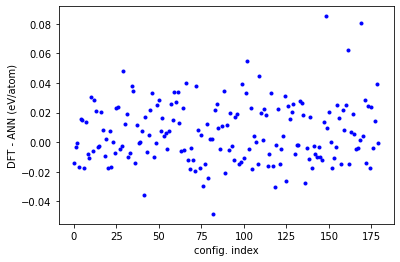

In [11]:
#Pandas have useful plotting tools but if you want to stick to matplotlib:
plt.plot((df['e_ref'] -df['e_nn'])/df['n_atoms'], 'b.')
plt.ylabel('DFT - ANN (eV/atom)')
plt.xlabel('config. index')
plt.show()

In [13]:
# Run this to cleanup the tutorial directory
# (do not remove these files if you want to follow part 3, converting the network to a lammps potential)
!cd {panna_cmdir+'/doc/tutorial'}; rm -rf mytrain mytrain_logs myvalidation tf.log